# MNIST: VGG16, ResNet34 y EfficientNetB0 con pesos ImageNet
Ejecuta las celdas en orden. Cada red tiene **su propia celda de entrenamiento**, una celda para sus **gráficas de pérdida y accuracy**, y una celda para ver su **resultado final de prueba**. No se hace comparación automática.

Se carga el mismo MNIST del archivo original mediante `tensorflow.keras.datasets.mnist.load_data()`. VGG16 y EfficientNetB0 usan Keras; ResNet34 usa Torchvision para disponer de su arquitectura y pesos ImageNet oficiales. En las tres se congela el extractor y se entrena un clasificador de 10 dígitos.

Las gráficas aparecerán al ejecutar el notebook. El archivo se entrega sin entrenamientos ejecutados ni resultados simulados. Recomendado: Google Colab con GPU o Jupyter con Python 3.11.


## 1. Instalar librerías
Si el entorno solicita reiniciar el kernel después de instalar, hazlo y continúa desde la siguiente celda.

In [1]:
%pip install tensorflow torch torchvision matplotlib scikit-learn tqdm


  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.2/127.2 MB 13.1 MB/s  0:00:09m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 13.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 13.0 MB/s  0:00:00
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [torchvision] [torchvision]
Note: you may need to restart the kernel to use updated packages.


## 2. Cargar MNIST y configurar
Por defecto se usan las 60.000 imágenes originales de entrenamiento (54.000 para entrenar y 6.000 para validar) y las 10.000 de prueba. Para una ejecución más corta puedes cambiar `N_ENTRENAMIENTO` a `5000`. Test nunca se usa como validación. Las imágenes se convierten en RGB por lote; no se almacena todo MNIST a 224×224 en memoria.

Entrenamiento: 54,000 | Validación: 6,000 | Prueba: 10,000
Resultados: /Users/unalmed/Downloads/resultados_mnist_imagenet/20261030_113137_9f872b


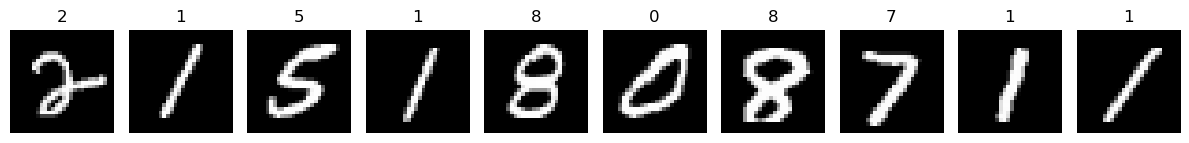

In [2]:
import os
os.environ["TF_FORCE_GPU_ALLOW_GROWTH"] = "true"
import gc
import json
from pathlib import Path
from datetime import datetime
from uuid import uuid4
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

SEMILLA = 42
EPOCAS = 5
BATCH_SIZE = 32
TAMANO = 224
LEARNING_RATE = 0.001
N_ENTRENAMIENTO = None  # None: todos; 5000: ejecución más corta

SALIDA = Path("resultados_mnist_imagenet") / (datetime.now().strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:6])
SALIDA.mkdir(parents=True)
tf.keras.utils.set_random_seed(SEMILLA)
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

(x_original, y_original), (x_test, y_test) = mnist.load_data()
idx_train, idx_val = train_test_split(np.arange(len(y_original)), test_size=0.1,
                                    random_state=SEMILLA, stratify=y_original)
if N_ENTRENAMIENTO is not None:
    if not 10 <= N_ENTRENAMIENTO <= len(idx_train):
        raise ValueError("N_ENTRENAMIENTO debe estar entre 10 y 54000, o ser None.")
    if N_ENTRENAMIENTO < len(idx_train):
        idx_train, _ = train_test_split(idx_train, train_size=N_ENTRENAMIENTO,
                                       random_state=SEMILLA, stratify=y_original[idx_train])
x_train, y_train = x_original[idx_train], y_original[idx_train]
x_val, y_val = x_original[idx_val], y_original[idx_val]
np.savez(SALIDA / "particiones.npz", train=idx_train, validation=idx_val)
(SALIDA / "configuracion.json").write_text(json.dumps({
    "epocas": EPOCAS, "batch_size": BATCH_SIZE, "tamano": TAMANO,
    "learning_rate": LEARNING_RATE, "semilla": SEMILLA,
    "n_train": len(y_train), "n_val": len(y_val), "n_test": len(y_test),
    "regimen": "ImageNet, extractor congelado, cabeza entrenada desde cero"
}, indent=2), encoding="utf-8")
print(f"Entrenamiento: {len(y_train):,} | Validación: {len(y_val):,} | Prueba: {len(y_test):,}")
print("Resultados:", SALIDA.resolve())
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(str(y_train[i])); ax.axis("off")
plt.tight_layout(); plt.show()


## 3. Preparación común para Keras y gráficas
Los datasets se generan de nuevo para cada red. Se emplean etiquetas enteras con entropía cruzada dispersa. La función de gráficas muestra entrenamiento y validación en dos paneles y guarda la imagen.

In [3]:
def datos_keras(imagenes, etiquetas, entrenar=False):
    ds = tf.data.Dataset.from_tensor_slices((imagenes[..., None], etiquetas))
    if entrenar:
        ds = ds.shuffle(len(etiquetas), seed=SEMILLA)
    return ds.batch(BATCH_SIZE).prefetch(1)

def entrada_rgb():
    entrada = layers.Input(shape=(28, 28, 1))
    x = layers.Resizing(TAMANO, TAMANO)(entrada)
    return entrada, layers.Concatenate()([x, x, x])

def graficar_historia(historia, nombre):
    h = historia.history if hasattr(historia, "history") else historia
    epocas = range(1, len(h["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metrica, titulo in zip(axes, ["loss", "accuracy"], ["Pérdida", "Accuracy"]):
        ax.plot(epocas, h[metrica], "o-", label="Entrenamiento")
        ax.plot(epocas, h["val_" + metrica], "o-", label="Validación")
        ax.set(title=f"{nombre}: {titulo}", xlabel="Época", ylabel=titulo)
        ax.set_xticks(list(epocas)); ax.grid(alpha=0.3); ax.legend()
        if metrica == "accuracy": ax.set_ylim(0, 1.02)
    plt.tight_layout()
    fig.savefig(SALIDA / f"{nombre}_curvas.png", dpi=160, bbox_inches="tight")
    plt.show()
    (SALIDA / f"{nombre}_historial.json").write_text(json.dumps(h, indent=2), encoding="utf-8")

def mostrar_resultado(nombre, loss, accuracy):
    from IPython.display import display, HTML
    display(HTML(f"<h3>{nombre} — resultado en MNIST de prueba</h3>"
                 f"<p style='font-size:22px'><b>Accuracy: {accuracy:.2%}</b>"
                 f" &nbsp; | &nbsp; <b>Pérdida: {loss:.4f}</b></p>"
                 f"<p>Evaluación sobre las {len(y_test):,} imágenes de prueba, con el mejor checkpoint de validación.</p>"))
    (SALIDA / f"{nombre}_prueba.json").write_text(
        json.dumps({"modelo": nombre, "test_loss": float(loss), "test_accuracy": float(accuracy),
                    "n_test": len(y_test)}, indent=2), encoding="utf-8")


## 4. VGG16 — entrenar
Pesos ImageNet, extractor congelado y cabeza Dense de 120, 84 y 10 unidades. VGG16 utiliza su preprocesamiento oficial. La barra muestra loss, accuracy, val_loss y val_accuracy por época.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)
entrada, x = entrada_rgb()
x = tf.keras.applications.vgg16.preprocess_input(x)
base_vgg16 = tf.keras.applications.VGG16(weights="imagenet", include_top=False,
                                        input_shape=(TAMANO, TAMANO, 3))
base_vgg16.trainable = False
x = base_vgg16(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(120, activation="relu")(x)
x = layers.Dense(84, activation="relu")(x)
salida = layers.Dense(10, activation="softmax")(x)
modelo_vgg16 = Model(entrada, salida, name="VGG16_MNIST")
modelo_vgg16.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])
historia_vgg16 = modelo_vgg16.fit(
    datos_keras(x_train, y_train, entrenar=True),
    validation_data=datos_keras(x_val, y_val), epochs=EPOCAS, verbose=1,
    callbacks=[tf.keras.callbacks.ModelCheckpoint(str(SALIDA / "vgg16.weights.h5"),
               monitor="val_loss", save_best_only=True, save_weights_only=True)])
modelo_vgg16.load_weights(SALIDA / "vgg16.weights.h5")


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Epoch 1/5
 152/1688 ━━━━━━━━━━━━━━━━━━━━ 1:02:49 2s/step - accuracy: 0.6600 - loss: 1.0586

### VGG16 — gráficas de pérdida y accuracy

In [ ]:
graficar_historia(historia_vgg16, "VGG16")


### VGG16 — resultado final de prueba
Se evalúa antes de liberar el modelo para dejar memoria disponible para la siguiente red.

In [ ]:
loss_vgg16, accuracy_vgg16 = modelo_vgg16.evaluate(datos_keras(x_test, y_test), verbose=1)
mostrar_resultado("VGG16", loss_vgg16, accuracy_vgg16)
del modelo_vgg16, base_vgg16, entrada, x, salida
tf.keras.backend.clear_session()
gc.collect()


## 5. ResNet34 — entrenar
Se usa **ResNet34 con pesos ImageNet oficiales de Torchvision**. Se congela el extractor, incluidas sus estadísticas BatchNorm, y se reemplaza la salida por un clasificador de 10 clases. Se aplica el preprocesamiento asociado a los pesos. La función de pérdida recibe logits y aplica internamente la operación equivalente a softmax + entropía cruzada. Cada época imprime las mismas cuatro métricas que Keras.

In [ ]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet34, ResNet34_Weights
from PIL import Image
from tqdm.auto import tqdm

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo ResNet34:", dispositivo)
torch.manual_seed(SEMILLA)
pesos_resnet34 = ResNet34_Weights.IMAGENET1K_V1
transformacion_resnet = pesos_resnet34.transforms()

class MNISTResNet(Dataset):
    def __init__(self, imagenes, etiquetas):
        self.imagenes, self.etiquetas = imagenes, etiquetas
    def __len__(self): return len(self.etiquetas)
    def __getitem__(self, indice):
        imagen = Image.fromarray(self.imagenes[indice]).convert("RGB")
        return transformacion_resnet(imagen), int(self.etiquetas[indice])

generador = torch.Generator().manual_seed(SEMILLA)
train_resnet = DataLoader(MNISTResNet(x_train, y_train), batch_size=BATCH_SIZE,
                          shuffle=True, generator=generador, num_workers=0)
val_resnet = DataLoader(MNISTResNet(x_val, y_val), batch_size=BATCH_SIZE, num_workers=0)
test_resnet = DataLoader(MNISTResNet(x_test, y_test), batch_size=BATCH_SIZE, num_workers=0)
modelo_resnet34 = resnet34(weights=pesos_resnet34)
for parametro in modelo_resnet34.parameters(): parametro.requires_grad = False
modelo_resnet34.fc = nn.Sequential(nn.Linear(modelo_resnet34.fc.in_features, 120), nn.ReLU(),
                                   nn.Linear(120, 84), nn.ReLU(), nn.Linear(84, 10))
modelo_resnet34.to(dispositivo)
optimizador_resnet = torch.optim.Adam(modelo_resnet34.fc.parameters(), lr=LEARNING_RATE)
criterio_resnet = nn.CrossEntropyLoss()
historia_resnet34 = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

def epoca_resnet(loader, entrenar=False):
    # Extractor siempre en eval: sus capas BatchNorm permanecen congeladas.
    modelo_resnet34.eval()
    modelo_resnet34.fc.train(entrenar)
    suma_loss, correctos, total = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for imagenes, etiquetas in tqdm(loader, leave=False, desc="Entrenamiento" if entrenar else "Evaluación"):
            imagenes, etiquetas = imagenes.to(dispositivo), etiquetas.to(dispositivo)
            if entrenar: optimizador_resnet.zero_grad(set_to_none=True)
            logits = modelo_resnet34(imagenes)
            loss = criterio_resnet(logits, etiquetas)
            if entrenar:
                loss.backward(); optimizador_resnet.step()
            suma_loss += loss.item() * len(etiquetas)
            correctos += (logits.argmax(1) == etiquetas).sum().item()
            total += len(etiquetas)
    return suma_loss / total, correctos / total

mejor_val_loss = float("inf")
for epoca in range(EPOCAS):
    loss, accuracy = epoca_resnet(train_resnet, entrenar=True)
    val_loss, val_accuracy = epoca_resnet(val_resnet)
    for clave, valor in zip(historia_resnet34, [loss, accuracy, val_loss, val_accuracy]):
        historia_resnet34[clave].append(float(valor))
    print(f"Época {epoca+1}/{EPOCAS} | loss: {loss:.4f} | accuracy: {accuracy:.4f} | "
          f"val_loss: {val_loss:.4f} | val_accuracy: {val_accuracy:.4f}", flush=True)
    if val_loss < mejor_val_loss:
        mejor_val_loss = val_loss
        torch.save(modelo_resnet34.state_dict(), SALIDA / "resnet34.pt")
modelo_resnet34.load_state_dict(torch.load(SALIDA / "resnet34.pt", map_location=dispositivo, weights_only=True))


### ResNet34 — gráficas de pérdida y accuracy

In [ ]:
graficar_historia(historia_resnet34, "ResNet34")


### ResNet34 — resultado final de prueba

In [ ]:
loss_resnet34, accuracy_resnet34 = epoca_resnet(test_resnet)
mostrar_resultado("ResNet34", loss_resnet34, accuracy_resnet34)
del modelo_resnet34, optimizador_resnet
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()


## 6. EfficientNetB0 — entrenar
Pesos ImageNet y extractor congelado. **No se divide por 255:** EfficientNetB0 de Keras ya incorpora el reescalado y recibe valores entre 0 y 255.

In [ ]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEMILLA)
entrada, x = entrada_rgb()
base_efficientnet = tf.keras.applications.EfficientNetB0(
    weights="imagenet", include_top=False, input_shape=(TAMANO, TAMANO, 3))
base_efficientnet.trainable = False
x = base_efficientnet(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(120, activation="relu")(x)
x = layers.Dense(84, activation="relu")(x)
salida = layers.Dense(10, activation="softmax")(x)
modelo_efficientnet = Model(entrada, salida, name="EfficientNetB0_MNIST")
modelo_efficientnet.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                           loss="sparse_categorical_crossentropy", metrics=["accuracy"])
historia_efficientnet = modelo_efficientnet.fit(
    datos_keras(x_train, y_train, entrenar=True),
    validation_data=datos_keras(x_val, y_val), epochs=EPOCAS, verbose=1,
    callbacks=[tf.keras.callbacks.ModelCheckpoint(str(SALIDA / "efficientnetb0.weights.h5"),
               monitor="val_loss", save_best_only=True, save_weights_only=True)])
modelo_efficientnet.load_weights(SALIDA / "efficientnetb0.weights.h5")


### EfficientNetB0 — gráficas de pérdida y accuracy

In [ ]:
graficar_historia(historia_efficientnet, "EfficientNetB0")


### EfficientNetB0 — resultado final de prueba

In [ ]:
loss_efficientnet, accuracy_efficientnet = modelo_efficientnet.evaluate(datos_keras(x_test, y_test), verbose=1)
mostrar_resultado("EfficientNetB0", loss_efficientnet, accuracy_efficientnet)
del modelo_efficientnet, base_efficientnet, entrada, x, salida
tf.keras.backend.clear_session()
gc.collect()



## Preguntas

- Cree una tabla y gráficas de comparación para las redes.
- Según los resultados Cual es la mejor red?


## Notas
  
- El extractor conserva pesos ImageNet; se entrena únicamente la cabeza nueva. No hay fine-tuning del extractor.
- Las métricas de las curvas corresponden al final de cada época; la evaluación de prueba usa los pesos con menor pérdida de validación.
- Las imágenes originales son las mismas para todas las redes. ResNet34 usa el redimensionado a 256 y recorte central a 224 del preprocesamiento oficial de sus pesos; VGG16 y EfficientNetB0 redimensionan directamente a `TAMANO` (224 por defecto).
- Si falta memoria GPU, reduce `BATCH_SIZE`. TensorFlow y PyTorch pueden conservar memoria en el mismo kernel; para liberarla completamente, reinicia el kernel y ejecuta carga de datos, funciones comunes y únicamente las celdas de la red que deseas entrenar.
- Los mejores pesos, historiales JSON, métricas de prueba y curvas PNG se guardan en la carpeta `SALIDA`. No hace falta ejecutar scripts externos.

Fuentes: [MNIST en Keras](https://keras.io/api/datasets/mnist/), [VGG16](https://keras.io/api/applications/vgg/), [ResNet34 y pesos oficiales](https://docs.pytorch.org/vision/main/models/generated/torchvision.models.resnet34), [EfficientNetB0 y su preprocesamiento](https://keras.io/api/applications/efficientnet/efficientnet_models/).
